# 03 · Preprocessing: pregătim datele pentru model

**Sursa:** [Preprocessing an audio dataset](https://huggingface.co/learn/audio-course/en/chapter1/preprocessing)
**Kernel:** `speech-vlm` (Mac)

**Cum folosești ghidul:**
- 📖 **Teorie**: ce trebuie să reții, pe scurt.
- ▶️ **Cod din curs**: îl rulezi și te uiți la rezultat.
- 🔍 **Ce să observi**: unde să te uiți în grafic sau în output.
- 🧪 **Exercițiu**: cerința e în comentariile `# TODO`, iar soluția e chiar dedesubt. O rulezi, apoi o modifici ca să vezi ce se schimbă.
- 🎯 **Legătura cu proiectul**.

> 💾 **Doar seturi mici:** folosim MINDS-14 (deja în cache, ~100 MB) și `librispeech_asr_dummy` (73 de exemple). Nu descărcăm seturi mari.

🎯 **De ce contează:** exact pașii ăștia îi aplicăm și datelor din proiect, înainte de encoderul Whisper: resampling la 16 kHz, filtrarea exemplelor prea lungi și feature extractor-ul.

In [1]:
import io, time
import numpy as np
import matplotlib.pyplot as plt
import librosa
import librosa.display
from IPython.display import Audio
from datasets import load_dataset, Audio as AudioFeature

/Users/bceachi/miniforge3/envs/speech-vlm/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


📖 **Cei trei pași ai preprocesării**
1. **Resampling**: aduci audio-ul la sampling rate-ul modelului.
2. **Filtrare**: scoți exemplele nepotrivite, de exemplu cele prea lungi.
3. **Input features**: transformi audio-ul în ce așteaptă modelul, cu **feature extractor-ul modelului**.

## 1. Resampling

📖 **Teorie**
- `load_dataset` îți dă audio-ul la sampling rate-ul cu care a fost publicat. MINDS-14 e la **8 kHz**, iar majoritatea modelelor pre-antrenate, inclusiv Whisper, vor **16 kHz**.
- `cast_column("audio", Audio(sampling_rate=16_000))` **nu modifică datele pe loc**. Doar îi spune lui `datasets` să resampleze **on-the-fly**, când încarci fiecare exemplu.
- **Upsampling** (8 → 16 kHz): se **calculează** valori noi între eșantioanele existente, prin interpolare. Nu apare informație nouă: tot nu există nimic peste 4 kHz, limita Nyquist a originalului.
- **Downsampling** (ex. 48 → 16 kHz): întâi trebuie **eliminate** frecvențele peste noul Nyquist (filtru anti-aliasing), altfel apar alias-uri. De aceea nu „arunci eșantioane”, ci lași librăriile (librosa, datasets) să facă resampling-ul.

▶️ **Cod din curs**

In [2]:
minds = load_dataset("PolyAI/minds14", name="en-AU", split="train")
a8 = minds[0]["audio"]
print(f"înainte: {a8['sampling_rate']} Hz, {len(a8['array'])} eșantioane")

minds = minds.cast_column("audio", AudioFeature(sampling_rate=16_000))
a16 = minds[0]["audio"]
print(f"după:    {a16['sampling_rate']} Hz, {len(a16['array'])} eșantioane")

înainte: 8000 Hz, 62415 eșantioane
după:    16000 Hz, 124830 eșantioane


🔍 **Ce să observi:** numărul de eșantioane s-a **dublat** (8 → 16 kHz), iar valorile din `array` s-au schimbat, pentru că au apărut valori noi, interpolate între cele vechi.

> În cod, `Audio` din `datasets` e importat ca `AudioFeature`, ca să nu se încurce cu `Audio` din IPython, pe care îl folosim pentru ascultare.

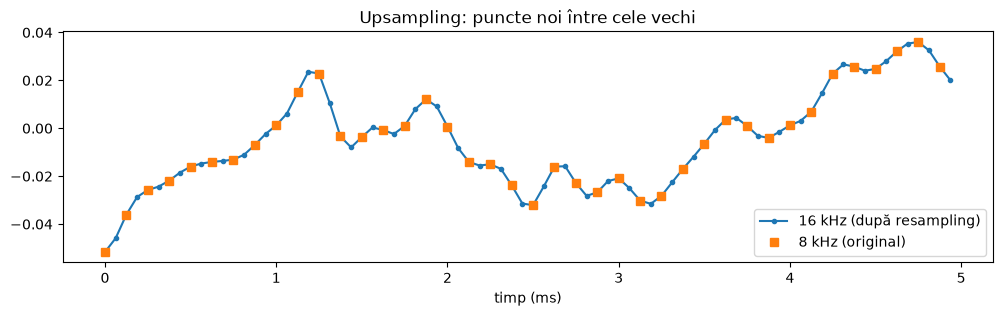

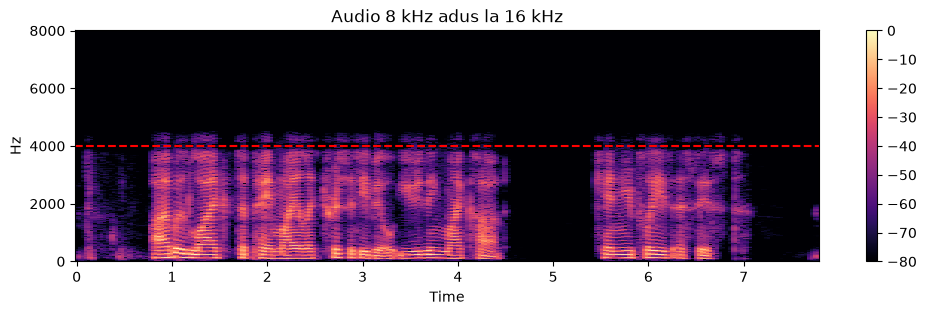

In [3]:
# 🧪 TODO 1: compară aceleași 5 ms la 8 kHz și la 16 kHz. Aceeași formă, dar de două ori mai multe puncte.
start = 8000                                   # aproximativ secunda 1 (la 8 kHz)
x8 = a8["array"][start:start + 40]             # 40 de eșantioane la 8 kHz = 5 ms
x16 = a16["array"][2 * start:2 * start + 80]   # 80 de eșantioane la 16 kHz = aceleași 5 ms
plt.figure(figsize=(12, 3))
plt.plot(np.arange(80) / 16, x16, "o-", ms=3, label="16 kHz (după resampling)")
plt.plot(np.arange(40) / 8, x8, "s", ms=6, label="8 kHz (original)")
plt.xlabel("timp (ms)"); plt.legend(); plt.title("Upsampling: puncte noi între cele vechi")
plt.show()

# 🧪 TODO 2: verifică faptul că upsampling-ul nu aduce informație nouă: spectrograma la 16 kHz nu are nimic peste 4 kHz.
S16 = librosa.amplitude_to_db(np.abs(librosa.stft(a16["array"])), ref=np.max)
plt.figure(figsize=(12, 3))
librosa.display.specshow(S16, x_axis="time", y_axis="hz", sr=16000)
plt.axhline(4000, color="red", linestyle="--"); plt.colorbar(); plt.title("Audio 8 kHz adus la 16 kHz")
plt.show()
# Răspuns: banda 4–8 kHz e goală, pentru că originalul (8 kHz) nu putea conține frecvențe peste 4 kHz (Nyquist).

In [4]:
# 🧪 TODO 3: de ce downsampling-ul NU înseamnă să arunci eșantioane.
# Un ton de 6 kHz la 16 kHz, adus la 8 kHz (unde Nyquist = 4 kHz) în două feluri: „naiv” și cu librosa.
t = np.arange(16000) / 16000
tone = (0.5 * np.sin(2 * np.pi * 6000 * t)).astype(np.float32)
naive = tone[::2]                                                  # aruncăm fiecare al doilea eșantion
proper = librosa.resample(tone, orig_sr=16000, target_sr=8000)     # cu filtru anti-aliasing

def peak_freq(y, sr):
    amp = np.abs(np.fft.rfft(y * np.hanning(len(y))))
    return np.fft.rfftfreq(len(y), 1 / sr)[np.argmax(amp)]
def rms(y):
    return float(np.sqrt(np.mean(np.square(y))))

print(f"naiv:   vârf la {peak_freq(naive, 8000):.0f} Hz, energie (RMS) {rms(naive):.3f}")
print(f"librosa: energie (RMS) {rms(proper):.4f}")
# Răspuns: varianta naivă produce un ton FALS de 2 kHz (8000 − 6000), adică aliasing.
# librosa filtrează întâi tot ce e peste 4 kHz, așa că tonul de 6 kHz dispare aproape complet, în loc să devină fals.

naiv:   vârf la 2000 Hz, energie (RMS) 0.354
librosa: energie (RMS) 0.0008


## 2. Filtrarea după durată

📖 **Teorie**
- Exemplele foarte lungi pot da **out-of-memory** la antrenare.
- Whisper **taie** tot ce trece de 30 s. Un exemplu tăiat are transcrierea completă, dar audio-ul incomplet, ceea ce strică antrenarea.
- `filter` primește o funcție care întoarce `True` (păstrezi exemplul) sau `False` (îl scoți). Cu `input_columns=["duration"]`, funcția primește direct valoarea din acea coloană.
- MINDS-14 nu are o coloană cu durata, așa că o creăm, filtrăm și apoi o ștergem.

▶️ **Cod din curs**

In [5]:
MAX_DURATION_IN_SECONDS = 20.0

def is_audio_length_in_range(input_length):
    return input_length < MAX_DURATION_IN_SECONDS

# durata fiecărui exemplu, calculată cu librosa
new_column = [librosa.get_duration(y=x["array"], sr=x["sampling_rate"]) for x in minds["audio"]]
minds = minds.add_column("duration", new_column)

# păstrăm doar exemplele sub 20 s
minds = minds.filter(is_audio_length_in_range, input_columns=["duration"])

# ștergem coloana ajutătoare
minds = minds.remove_columns(["duration"])
minds

Filter: 100%|██████████| 654/654 [00:00<00:00, 78181.46 examples/s]


Dataset({
    features: ['path', 'audio', 'transcription', 'english_transcription', 'intent_class', 'lang_id'],
    num_rows: 624
})

🔍 **Ce să observi:** dataset-ul scade de la **654** la **624** de exemple. Au fost scoase 30 de exemple mai lungi de 20 s.

peste 20 s: 30 | peste 30 s: 3 | din 654


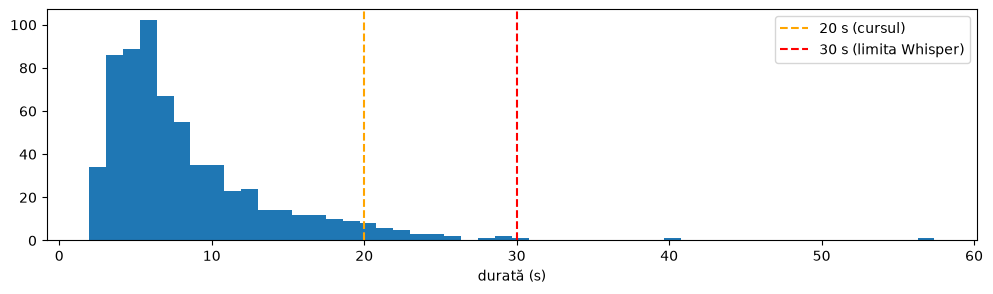

In [6]:
# 🧪 TODO: pentru Whisper, pragul relevant e 30 s. Câte exemple ar fi tăiate de Whisper?
# TODO: desenează histograma duratelor, cu liniile de 20 s și 30 s.
durations = np.array(new_column)
print(f"peste 20 s: {(durations > 20).sum()} | peste 30 s: {(durations > 30).sum()} | din {len(durations)}")
plt.figure(figsize=(12, 3))
plt.hist(durations, bins=50)
plt.axvline(20, color="orange", linestyle="--", label="20 s (cursul)")
plt.axvline(30, color="red", linestyle="--", label="30 s (limita Whisper)")
plt.xlabel("durată (s)"); plt.legend(); plt.show()
# Răspuns: 30 de exemple au peste 20 s, dar doar 3 au peste 30 s.
# În proiect filtrăm la 30 s, exact limita Whisper.

## 3. Feature extractor-ul: din audio în ce „vede” modelul

📖 **Teorie**
- Fiecare model pre-antrenat așteaptă intrarea într-un anumit format. Pentru fiecare model audio, 🤗 Transformers are un **feature extractor** care face conversia.
- **Feature extractor-ul Whisper:**
  1. completează cu zerouri sau taie fiecare exemplu la **30 s**;
  2. calculează **log-mel spectrogram-ul**: 80 de benzi la `whisper-small`, **128 la turbo**.
- Pentru că toate exemplele au exact 30 s, Whisper **nu are nevoie de attention mask**, adică nu trebuie să-i spui unde e padding. Învață singur să ignore liniștea.
- Majoritatea celorlalte modele audio au nevoie de attention mask.

▶️ **Cod din curs**
> Cursul aplică `map` pe tot dataset-ul. Aici îl aplicăm pe 100 de exemple, ca să meargă repede și să nu umple cache-ul.

In [7]:
from transformers import WhisperFeatureExtractor

feature_extractor = WhisperFeatureExtractor.from_pretrained("openai/whisper-small")

def prepare_dataset(example):
    audio = example["audio"]
    features = feature_extractor(audio["array"], sampling_rate=audio["sampling_rate"], padding=True)
    return features

minds_feat = minds.select(range(100)).map(prepare_dataset)
minds_feat

Map: 100%|██████████| 100/100 [00:00<00:00, 407.57 examples/s]


Dataset({
    features: ['path', 'audio', 'transcription', 'english_transcription', 'intent_class', 'lang_id', 'input_features'],
    num_rows: 100
})

input_features: (1, 80, 780)


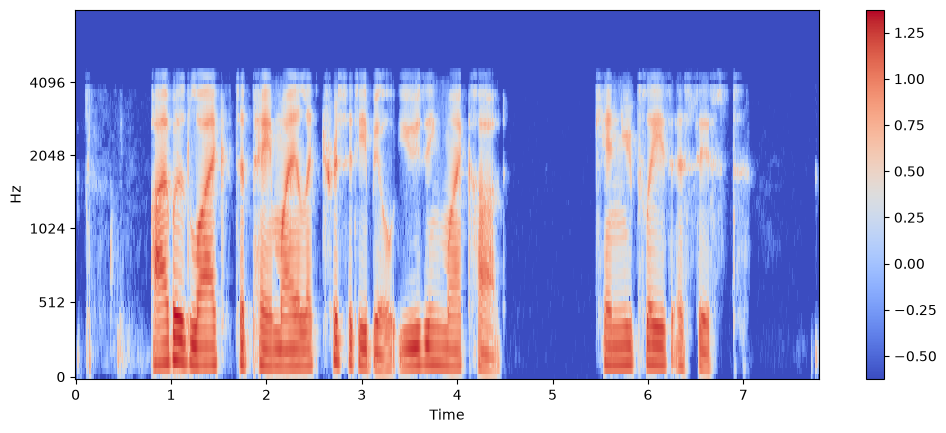

In [8]:
example = minds_feat[0]
input_features = np.asarray(example["input_features"])
print("input_features:", input_features.shape)

plt.figure().set_figwidth(12)
librosa.display.specshow(
    input_features[0], x_axis="time", y_axis="mel",
    sr=feature_extractor.sampling_rate, hop_length=feature_extractor.hop_length,
)
plt.colorbar()
plt.show()

🔍 **Ce să observi:**
- Asta e intrarea Whisper: un **log-mel spectrogram** cu 80 de benzi, la 100 de cadre pe secundă.
- ⚠️ **Atenție la shape:** a ieșit `(1, 80, N)` cu N < 3000, nu `(1, 80, 3000)`. Cu versiunile actuale de transformers, **`padding=True` completează doar până la cel mai lung exemplu din batch**. Aici batch-ul e un singur exemplu, deci nu se adaugă nimic.
- Pentru Whisper, apelul corect e **fără** argumentul `padding`. Valoarea implicită, `"max_length"`, completează până la **30 s = 3000 de cadre**.

padding=True: (1, 80, 780) | implicit: (1, 80, 3000) | durata audio = 7.8 s


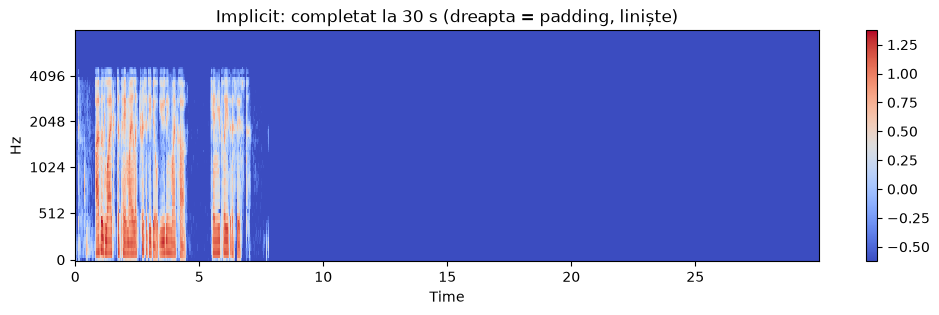

turbo: (1, 128, 3000)


In [9]:
# 🧪 TODO 1: apelul corect pentru Whisper (fără padding=True) și comparația de shape-uri.
audio = minds[0]["audio"]
f_true = feature_extractor(audio["array"], sampling_rate=16000, padding=True, return_tensors="np").input_features
f_ok = feature_extractor(audio["array"], sampling_rate=16000, return_tensors="np").input_features
print(f"padding=True: {f_true.shape} | implicit: {f_ok.shape} | durata audio = {len(audio['array']) / 16000:.1f} s")

plt.figure(figsize=(12, 3))
librosa.display.specshow(f_ok[0], x_axis="time", y_axis="mel", sr=16000, hop_length=160)
plt.colorbar(); plt.title("Implicit: completat la 30 s (dreapta = padding, liniște)")
plt.show()
# Răspuns: implicit iese (1, 80, 3000). E ce așteaptă encoderul Whisper: mereu 3000 de cadre.

# 🧪 TODO 2: feature extractor-ul modelului din proiect (Whisper turbo) are 128 de benzi.
fe_turbo = WhisperFeatureExtractor.from_pretrained("openai/whisper-large-v3-turbo")
print("turbo:", fe_turbo(audio["array"], sampling_rate=16000, return_tensors="np").input_features.shape)
# Răspuns: (1, 128, 3000). Tot 30 s, dar cu 128 de benzi mel în loc de 80.

## 4. Processor = feature extractor + tokenizer

📖 **Teorie**
- La ASR ai **două** tipuri de date:
  - **audio** (intrarea), procesat de **feature extractor**;
  - **text** (transcrierea), procesat de **tokenizer**: text ↔ numere (tokeni).
- **Processor-ul** le împachetează pe amândouă într-un singur obiect. Îl încarci cu `AutoProcessor.from_pretrained(...)`.

▶️ **Cod din curs**

In [10]:
from transformers import AutoProcessor

processor = AutoProcessor.from_pretrained("openai/whisper-small")
print(type(processor).__name__, "=", type(processor.feature_extractor).__name__, "+", type(processor.tokenizer).__name__)

W1123 17:52:57.319000 99373 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


WhisperProcessor = WhisperFeatureExtractor + WhisperTokenizer


In [11]:
# 🧪 TODO: transformă o transcriere în tokeni și înapoi. Ce tokeni speciali adaugă Whisper?
text = minds[0]["transcription"]
ids = processor.tokenizer(text).input_ids
print("text:  ", text)
print("tokeni:", ids)
print("decodat cu tokenii speciali:", processor.tokenizer.decode(ids, skip_special_tokens=False))
print("decodat fără:               ", processor.tokenizer.decode(ids, skip_special_tokens=True))
# Răspuns: Whisper pune tokeni speciali la început, de exemplu <|startoftranscript|> și <|notimestamps|>, și <|endoftext|> la final.
# 🎯 În proiect vom adăuga și noi tokeni speciali (<|audio_start|>, <|audio_pad|>, <|audio_end|>), dar în tokenizer-ul Qwen.

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer WhisperTokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


text:   I would like to pay my electricity bill using my card can you please assist
tokeni: [50258, 50363, 40, 576, 411, 281, 1689, 452, 10356, 2961, 1228, 452, 2920, 393, 291, 1767, 4255, 50257]
decodat cu tokenii speciali: <|startoftranscript|><|notimestamps|>I would like to pay my electricity bill using my card can you please assist<|endoftext|>
decodat fără:                I would like to pay my electricity bill using my card can you please assist


## 5. 🎯 Legătura cu proiectul

Pentru fiecare exemplu din `LoquaciousSet`:

| Pas | MINDS-14 (aici) | Proiect |
|---|---|---|
| Decodare | automată (`datasets`) | din **bytes WAV**, cu `soundfile` |
| Resampling | 8 → 16 kHz | dataset-ul e deja la 16 kHz (de confirmat) |
| Filtrare | < 20 s | **< 30 s** (limita Whisper) |
| Features | whisper-small: (1, 80, 3000) | **Whisper turbo: (1, 128, 3000)** |
| Text | tokenizer-ul Whisper | tokenizer-ul **Qwen2-VL**, cu tokenii audio adăugați de noi |

## 📌 Ce trebuie să reții
- Preprocesarea are trei pași: **resampling → filtrare → input features**.
- `cast_column(..., Audio(sampling_rate=16_000))` resamplează **on-the-fly**, la încărcare.
- **Upsampling-ul** nu aduce informație nouă. **Downsampling-ul** cere un filtru anti-aliasing, deci folosești librării.
- Scoți exemplele prea lungi: memorie, plus Whisper taie la 30 s.
- **Feature extractor-ul modelului** face exact transformarea de la antrenare. Whisper: 30 s → log-mel → (1, n_mels, 3000), fără attention mask.
- ⚠️ Cu transformers actual, `padding=True` nu completează la 30 s. Pentru Whisper folosești apelul implicit.
- **Processor** = feature extractor + tokenizer.

## ❓ Verifică-te
<details><summary><b>1. De ce nu modifică `cast_column` datele pe loc?</b></summary>

Doar schimbă tipul coloanei. Resampling-ul se face **on-the-fly**, când accesezi fiecare exemplu. E rapid de setat și nu duplică datele pe disk.

</details>

<details><summary><b>2. Ce câștigi când faci upsampling de la 8 la 16 kHz?</b></summary>

Nicio informație nouă: banda 4–8 kHz rămâne goală. Câștigi doar **compatibilitatea** cu modelul, care așteaptă 16 kHz.

</details>

<details><summary><b>3. De ce filtrăm exemplele de peste 30 s în proiect?</b></summary>

Whisper taie la 30 s, deci transcrierea ar conține cuvinte pe care audio-ul primit de model nu le mai are. În plus, exemplele lungi consumă multă memorie.

</details>

<details><summary><b>4. De ce Whisper nu are nevoie de attention mask?</b></summary>

Toate intrările au exact 30 s (3000 de cadre), iar modelul a învățat să ignore singur zona de padding.

</details>

<details><summary><b>5. Ce shape primește encoderul Whisper turbo?</b></summary>

**(1, 128, 3000)**: 128 de benzi mel × 3000 de cadre de 10 ms.

</details>

<details><summary><b>6. Ce face un processor?</b></summary>

Împachetează **feature extractor-ul** (audio → features) și **tokenizer-ul** (text ↔ tokeni), ca să lucrezi cu un singur obiect.

</details>

## ➡️ Următorul: [04_streaming.ipynb](04_streaming.ipynb)